In [ ]:
import zipfile
from tensorflow.keras.utils import image_dataset_from_directory
import tensorflow as tf

zipfile.ZipFile("archive.zip").extractall("data")

train_data = image_dataset_from_directory("data/train", image_size=(48,48), color_mode="grayscale")
test_data = image_dataset_from_directory("data/test", image_size=(48,48), color_mode="grayscale")

normalization_layer = tf.keras.layers.Rescaling(1./255)
train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
test_data = test_data.map(lambda x, y: (normalization_layer(x), y))

In [ ]:
import random
import numpy as np
import tensorflow as tf

SEED_VALUE = 9999

random.seed(SEED_VALUE)
np.random.seed(SEED_VALUE)
tf.random.set_seed(SEED_VALUE)

In [3]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

model = Sequential([
    Flatten(input_shape=(48, 48, 1)),  # Flattens 4x48 image into 2304 inputs
    Dense(128, activation='relu'),       # Hidden layer 1
    Dense(64, activation='relu'),        # Hidden layer 2
    Dense(7, activation='softmax')       # Output layer for 7 emotion classes
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 303,751 (1.16 MB)

 Trainable params: 303,751 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train for a few epochs
history = model.fit(train_data, validation_data= test_data, epochs=5)

test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc:.4f}")

model.save("emotion_model.keras")

Epoch 1/5


C:\Users\alija\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


898/898 ━━━━━━━━━━━━━━━━━━━━ 65s 70ms/step - accuracy: 0.2857 - loss: 1.7679
Epoch 2/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.3356 - loss: 1.6890
Epoch 3/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.3468 - loss: 1.6601
Epoch 4/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.3570 - loss: 1.6359
Epoch 5/5
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.3610 - loss: 1.6258
225/225 ━━━━━━━━━━━━━━━━━━━━ 18s 79ms/step - accuracy: 0.3727 - loss: 1.6199
Test Accuracy: 0.3727


NameError: name 'history' is not defined

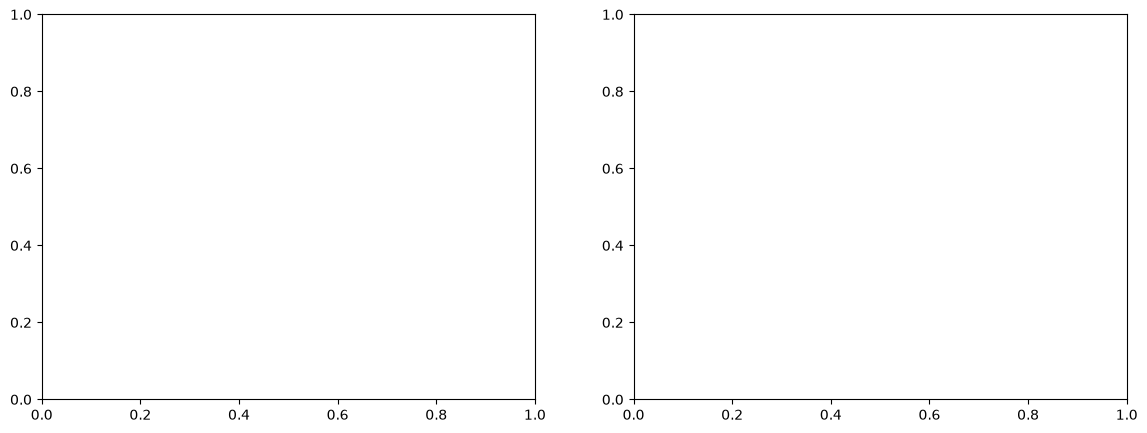

In [2]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history.history['accuracy'], label='Train')
ax1.plot(history.history['val_accuracy'], label='Validation')
ax1.set_title('Accuracy')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid(True)

# Loss
ax2.plot(history.history['loss'], label='Train')
ax2.plot(history.history['val_loss'], label='Validation')
ax2.set_title('Loss')
ax2.set_xlabel('Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()